# 4장 경사 하강에 의한 추론, 행동, 학습 (실습)

자유 에너지를 줄이는 네 가지 길이 모두 경사 하강 식 하나로 구현된다는 주장을 확인한다.

1. 정적 추론: 학습률에 따라 경사 하강이 어떻게 수렴하는가
2. 동적 추론: 일반화 좌표의 Dμ̃ 항은 움직이는 대상을 쫓을 때 무엇을 바꾸는가
3. 행동: 감각을 거쳐 연쇄 법칙으로 내린 행동의 경사 하강이 원하는 상태로 데려가는가
4. 학습과 주의: 느린 경사 하강(DEM 의 E 단계와 M 단계)이 생성 모델의 매개변수와 잡음 크기를 찾아내는가
5. 예측 부호화: 오차 뉴런을 따로 둔 회로가 같은 답을 내는가

마지막으로 학습률이 너무 크면 경사 하강이 어떻게 무너지는지 본다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

def makeNoise(C, s2, t):
    """공분산 C, 매끄러움 s2 인 유색 잡음 (2장과 같은 함수)."""
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 < 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

print("준비 완료, numpy", np.__version__)

준비 완료, numpy 2.5.4


## 1. 정적 추론의 경사 하강

1장의 문제(사전 N(3, 1), g(x) = 2x, 감각 분산 1, y = 8)로 학습률만 바꿔 본다. 이 자유 에너지의 곡률은 g'² /σ_z² + 1/σ_w² = 5 이므로, 이론상 학습률이 2/5 = 0.4 보다 작아야 수렴한다.

In [2]:
v, s2_w, s2_z, y = 3.0, 1.0, 1.0, 8.0
g, dg = (lambda x: 2 * x), 2.0
F = lambda m: (y - g(m))**2 / (2 * s2_z) + (m - v)**2 / (2 * s2_w)
dF = lambda m: -dg * (y - g(m)) / s2_z + (m - v) / s2_w

def descend(lr, steps=60, m=v):
    path = [m]
    for _ in range(steps):
        m = m - lr * dF(m)
        path.append(m)
    return np.array(path)

print("학습률   10걸음 μ   60걸음 μ   (정답 3.8)")
for lr in [0.02, 0.1, 0.2, 0.35]:
    p = descend(lr)
    print(f"{lr:5.2f}   {p[10]:8.4f}   {p[60]:8.4f}")

학습률   10걸음 μ   60걸음 μ   (정답 3.8)
 0.02     3.5211     3.7986
 0.10     3.7992     3.8000
 0.20     3.8000     3.8000
 0.35     3.7549     3.8000


## 2. 움직이는 대상을 쫓는다 — Dμ̃ 항의 역할

숨은 상태가 2 초 동안 속도 2 로 움직이다가 4 에서 멈춘다. 감각은 위치와 그 시간 도함수(일반화 감각 y, y′)다. 믿음은 위치와 속도 [μ, μ′] 로 둔다. 두 가지 갱신 규칙을 비교한다.

- Dμ̃ 항 있음: μ̇ = μ′ − α ∂F/∂μ,  μ̇′ = −α ∂F/∂μ′
- Dμ̃ 항 없음: μ̇ = −α ∂F/∂μ (믿음이 스스로 움직이지 않는다)

In [3]:
dt = 0.005
t = np.arange(0, 4 + dt / 2, dt)
N = t.size
x_true = np.where(t < 2, 2 * t, 4.0)                  # 움직이다 멈춘다
np.random.seed(5)
y = x_true + makeNoise(0.01, 1 / 64, t)[0]
y1 = np.gradient(y, dt)                               # 감각의 속도 (일반화 감각)
s0, s1, alpha = 0.01, 0.32, 0.2                       # 위치·속도 감각 분산, 학습률

def track(use_D):
    mu, mu1, out = 0.0, 0.0, np.zeros(N)
    for i in range(N):
        e0, e1 = y[i] - mu, y1[i] - mu1               # 감각 예측 오차 (위치, 속도)
        dmu = (mu1 if use_D else 0.0) + alpha * e0 / s0
        dmu1 = alpha * e1 / s1
        mu, mu1 = mu + dt * dmu, mu1 + dt * dmu1
        out[i] = mu
    return out

for use_D in [True, False]:
    m = track(use_D)
    ramp = (t > 0.5) & (t < 2)
    lag = np.mean(x_true[ramp] - m[ramp])
    over = m[t > 2].max() - 4
    print(f"Dμ̃ 항 {'있음' if use_D else '없음'}: 움직이는 동안 평균 뒤처짐 {lag:+.4f}, 멈춘 뒤 최대 넘침 {over:+.4f}")
mu_D, mu_noD = track(True), track(False)

Dμ̃ 항 있음: 움직이는 동안 평균 뒤처짐 +0.0340, 멈춘 뒤 최대 넘침 +0.1013
Dμ̃ 항 없음: 움직이는 동안 평균 뒤처짐 +0.0846, 멈춘 뒤 최대 넘침 +0.0603


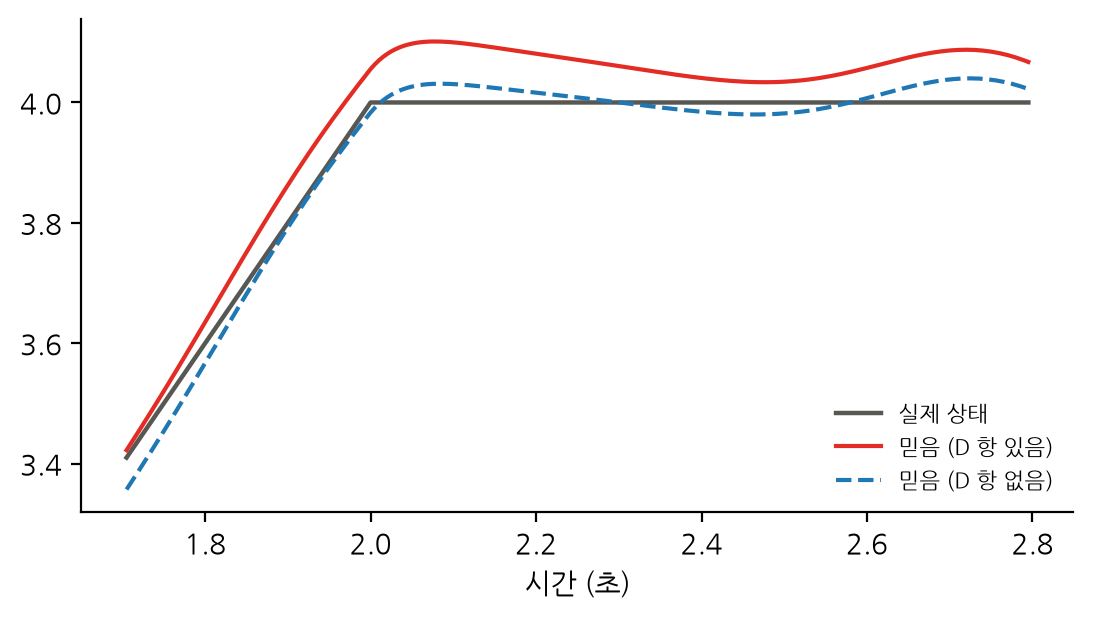

In [4]:
sel = (t > 1.7) & (t < 2.8)
plt.plot(t[sel], x_true[sel], color="#575753", lw=1.6, label="실제 상태")
plt.plot(t[sel], mu_D[sel], color="#E32C24", label="믿음 (D 항 있음)")
plt.plot(t[sel], mu_noD[sel], "--", color="#1f77b4", label="믿음 (D 항 없음)")
plt.xlabel("시간 (초)")
plt.legend(frameon=False, fontsize=8)
plt.show()

## 3. 행동의 경사 하강

깊이 x 에서 수온은 g(x) = 25 − 2x 다(깊을수록 차갑다). Hydar 는 수온 17 도, 곧 깊이 4 에 있기를 바란다. 이 바람은 숨은 상태에 대한 사전 믿음 v = 4 로 들어간다. 행동 u 는 깊이의 속도다(ẋ = u). 행동은 생성 모델에 없고, 감각을 거친 연쇄 법칙 u̇ = −α_u (∂y/∂u) ∂F/∂y 로만 정해진다.

In [5]:
g_T, dg_T = (lambda x: 25 - 2 * x), -2.0
v_des, s2_w, s2_z = 4.0, 1.0, 0.1
a_mu, a_u = 1.0, 1.0
np.random.seed(9)
x, mu, u = 0.0, 0.0, 0.0
log = []
for i in range(int(10 / dt)):
    y_T = g_T(x) + 0.05 * np.random.randn()           # 수온 감각
    e_y, e_x = y_T - g_T(mu), mu - v_des
    mu -= dt * a_mu * (-dg_T * e_y / s2_z + e_x / s2_w)   # 지각
    dF_dy = e_y / s2_z
    u -= dt * a_u * dg_T * dF_dy                       # 행동: ∂y/∂u 의 부호는 g' 와 같다
    x += dt * u
    log.append((i * dt, x, y_T, mu))
log = np.array(log)
for sec in [0, 1, 2, 4, 6, 9.99]:
    k = int(sec / dt)
    print(f"t={log[k, 0]:5.2f}s  깊이 x={log[k, 1]:5.2f}  수온 y={log[k, 2]:5.2f}  믿음 μ={log[k, 3]:5.2f}")

t= 0.00s  깊이 x= 0.00  수온 y=25.00  믿음 μ= 0.02
t= 1.00s  깊이 x= 1.33  수온 y=22.30  믿음 μ= 1.35
t= 2.00s  깊이 x= 3.40  수온 y=18.19  믿음 μ= 3.38
t= 4.00s  깊이 x= 4.65  수온 y=15.77  믿음 μ= 4.63
t= 6.00s  깊이 x= 4.00  수온 y=17.06  믿음 μ= 4.02
t= 9.99s  깊이 x= 4.01  수온 y=17.00  믿음 μ= 4.01


## 4. 학습과 주의 — DEM 의 D·E·M 단계

200 번의 시행마다 맥락 v_k 가 주어지고, 숨은 상태는 x_k ~ N(v_k, 0.3²), 감각은 y_k = 2 x_k + N(0, 0.5²) 로 생긴다. 생성 모델은 g(x) = θx 이지만 θ 와 감각 분산 σ_z² 를 모른다(처음엔 θ = 0.5, σ_z² = 4). 에폭마다 다음을 되풀이한다.

- D 단계: 각 시행의 숨은 상태 μ_k 를 경사 하강으로 추론하고, 그 자리의 곡률로 라플라스 사후 분산 σ_q² 를 얻는다 (빠름)
- E 단계: 모든 시행의 자유 에너지 합(자유 작용)의 기울기로 θ 를 고친다. 학습률은 곡률로 나눠 정한다 (느림)
- M 단계: 자유 에너지를 최소로 하는 σ_z² 로 고친다 (느림)

In [6]:
rng = np.random.default_rng(11)
K = 200
v_k = rng.uniform(1, 5, K)
x_k = v_k + rng.normal(0, 0.3, K)
y_k = 2.0 * x_k + rng.normal(0, 0.5, K)
s2_x = 0.3**2

def dem(epochs=31, use_var=True, report=True):
    theta, s2_y, trace = 0.5, 4.0, []
    for epoch in range(epochs):
        trace.append((epoch, theta, s2_y))
        if s2_y < 1e-10:                                          # σ_z² 가 0 으로 무너졌다
            break
        curv = theta**2 / s2_y + 1 / s2_x                       # D 단계
        s2_q = 1 / curv if use_var else 0.0                     # 라플라스 사후 분산
        mu = v_k.copy()
        for _ in range(100):
            mu -= (0.5 / curv) * (-theta * (y_k - theta * mu) / s2_y + (mu - v_k) / s2_x)
        e_y = y_k - theta * mu
        if report and epoch % 5 == 0:
            F = (e_y**2 + theta**2 * s2_q) / (2 * s2_y) + ((mu - v_k)**2 + s2_q) / (2 * s2_x) \
                + 0.5 * np.log(s2_y * s2_x) - 0.5 * np.log(s2_q if use_var else 1.0)
            print(f"{epoch:3d}  {theta:6.3f}  {s2_y:7.4f}  {F.mean():7.3f}")
        grad = np.sum(-e_y * mu + theta * s2_q) / s2_y               # E 단계
        theta -= 0.5 * grad / np.sum((mu**2 + s2_q) / s2_y)
        s2_y = np.mean(e_y**2) + theta**2 * s2_q                      # M 단계
    return theta, s2_y, trace

print("에폭   θ       σ_z²     평균 F")
theta_hat, s2_hat, _ = dem()
print(f"참값 θ = 2, σ_z² = 0.25  (이 표본의 실제 잡음 분산 {np.mean((y_k - 2 * x_k)**2):.3f})")

에폭   θ       σ_z²     평균 F
  0   0.500   4.0000    3.996
  5   1.917   0.7542    0.868
 10   1.981   0.3675    0.785
 15   1.994   0.3107    0.781
 20   1.997   0.2939    0.780
 25   1.998   0.2881    0.780
 30   1.999   0.2860    0.780
참값 θ = 2, σ_z² = 0.25  (이 표본의 실제 잡음 분산 0.239)


## 5. 예측 부호화 회로 — 오차 뉴런을 따로 둔다

보가츠(Bogacz)의 형식은 예측 오차를 믿음과 같은 신경 상태로 두고, 오차 역시 미분 방정식을 따라 움직이게 한다. 수렴하면 오차 뉴런의 값은 정밀도 가중 예측 오차가 된다. 1절의 문제로 직접 경사 하강과 비교한다.

In [7]:
v, s2_w, s2_z, y = 3.0, 1.0, 1.0, 8.0
mu, xi_x, xi_y = v, 0.0, 0.0
h = 0.01
for _ in range(5000):
    d_xi_x = (mu - v) - s2_w * xi_x               # 사전 오차 뉴런
    d_xi_y = (y - g(mu)) - s2_z * xi_y            # 감각 오차 뉴런
    d_mu = -xi_x + dg * xi_y                      # 믿음 뉴런은 오차 뉴런의 입력만 더한다
    mu, xi_x, xi_y = mu + h * d_mu, xi_x + h * d_xi_x, xi_y + h * d_xi_y
print(f"예측 부호화 회로 μ = {mu:.4f}   직접 경사 하강 μ = {descend(0.1, 200)[-1]:.4f}")
print(f"오차 뉴런 ξ_x = {xi_x:.4f}   (μ − v)/σ_w² = {(mu - v) / s2_w:.4f}")
print(f"오차 뉴런 ξ_y = {xi_y:.4f}   (y − g(μ))/σ_z² = {(y - g(mu)) / s2_z:.4f}")

예측 부호화 회로 μ = 3.8000   직접 경사 하강 μ = 3.8000
오차 뉴런 ξ_x = 0.8000   (μ − v)/σ_w² = 0.8000
오차 뉴런 ξ_y = 0.4000   (y − g(μ))/σ_z² = 0.4000


## 6. 실패 조건 둘

첫째, 1절의 문제에서 학습률을 이론 한계 0.4 근처와 그 너머로 올린다. 둘째, 4절의 학습에서 라플라스 사후 분산 σ_q² 를 빼고 점 추정 μ 만으로 θ 와 σ_z² 를 학습한다.

In [8]:
print("학습률   5걸음 μ    20걸음 μ      60걸음 μ")
for lr in [0.38, 0.40, 0.42, 0.5]:
    p = descend(lr)
    print(f"{lr:5.2f}  {p[5]:9.3f}  {p[20]:9.3f}  {p[60]:12.3e}")

학습률   5걸음 μ    20걸음 μ      60걸음 μ
 0.38      4.272      3.703     3.799e+00
 0.40      4.600      3.000     3.000e+00
 0.42      5.088     -1.582    -2.398e+02
 0.50      9.875  -2656.405    -2.941e+10


In [9]:
for use_var in [True, False]:
    _, _, tr = dem(use_var=use_var, report=False)
    row = "  ".join(f"{e}:{s2:.3g}" for e, _, s2 in tr[::3])
    print(f"사후 분산 {'넣음' if use_var else '뺌 '}  에폭:σ_z²  {row}")
    print(f"    마지막 에폭 {tr[-1][0]}, θ = {tr[-1][1]:.3f}, σ_z² = {tr[-1][2]:.3g}")

사후 분산 넣음  에폭:σ_z²  0:4  3:2.33  6:0.579  9:0.393  12:0.335  15:0.311  18:0.299  21:0.292  24:0.289  27:0.287  30:0.286
    마지막 에폭 30, θ = 1.999, σ_z² = 0.286
사후 분산 뺌   에폭:σ_z²  0:4  3:1.95  6:0.199  9:0.00357  12:2.89e-15
    마지막 에폭 12, θ = 1.972, σ_z² = 2.89e-15


## 결론

- 정적 추론에서 경사 하강은 학습률이 곡률로 정해지는 한계보다 작으면 정답에 수렴하고, 클수록 빨리 수렴한다.
- 일반화 좌표의 Dμ̃ 항이 있으면 믿음이 추정한 속도로 스스로 움직여, 움직이는 대상을 거의 뒤처지지 않고 쫓는다. 대신 대상이 갑자기 멈추면 믿음이 잠시 앞으로 미끄러진다. 운동 잔상과 같은 모양이다.
- 행동을 감각을 거친 연쇄 법칙으로 내리면, 생성 모델에 행동이 없는데도 Hydar 는 바라는 수온의 깊이로 간다.
- 빠른 D 단계와 느린 E·M 단계를 번갈아 돌리면 생성 모델의 매개변수 θ 와 감각 잡음 σ_z² 가 참값 근처로 가고 평균 자유 에너지가 내려간다. 이때 라플라스 사후 분산을 빼면 믿음이 감각 오차를 모두 흡수해 σ_z² 가 0 으로 무너진다.
- 오차 뉴런을 따로 둔 예측 부호화 회로는 직접 경사 하강과 같은 답을 내고, 오차 뉴런의 값은 정밀도 가중 예측 오차가 된다.
- 학습률이 곡률 한계 2/곡률을 넘으면 경사 하강은 진동하며 발산한다.